# TP SVM — Approximation de la consommation de carburant (Auto MPG)

**Objectif** : prédire la consommation `mpg` (miles per gallon) des véhicules à partir de leurs caractéristiques, en traitant le problème :

1. **comme une classification** (consommation *faible / moyenne / élevée*) avec un **SVC** linéaire et à noyaux ;
2. **comme une régression** avec un **SVR linéaire** (perte ε-insensible).

Pour chaque approche on va :
- justifier un **pipeline de prétraitement** ;
- coder le modèle **depuis zéro** (uniquement avec `numpy`) ;
- **comparer** avec l'implémentation de `scikit-learn`.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Imports |
| 1 | Chargement et exploration des données |
| 2 | Prétraitement (nettoyage, encodage, standardisation, découpage) |
| 3 | Classification : discrétisation de la cible |
| 4 | SVC from scratch (SMO + noyaux) |
| 5 | Comparaison avec `sklearn.svm.SVC` |
| 6 | Régression : SVR linéaire from scratch |
| 7 | Comparaison avec `sklearn` (`SVR`, `LinearSVR`) |
| 8 | Influence de ε : vecteurs de support et bruit |
| 9 | Conclusion |

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# scikit-learn : utilisé UNIQUEMENT pour comparer avec nos implémentations
from sklearn.svm import SVC, SVR, LinearSVR
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Chargement et exploration des données

Le jeu de données **Auto MPG** est disponible directement dans `seaborn`.
Il contient des variables **continues** (`displacement`, `horsepower`, `weight`, `acceleration`, `model_year`) et des variables **catégorielles** (`cylinders`, `origin`).
La colonne `name` (nom de la voiture) est un simple identifiant.

In [2]:
df = sns.load_dataset("mpg")
print("Taille brute :", df.shape)
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())
df.head()

Taille brute : (398, 9)

Valeurs manquantes par colonne :
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


On observe que `horsepower` a **6 valeurs manquantes**. Comme il n'y en a que 6 sur 398 lignes, le plus simple et le plus sûr est de **supprimer ces lignes** (on obtient bien les 392 échantillons de l'énoncé). On supprime aussi `name` : c'est un identifiant à très forte cardinalité qui n'apporte pas d'information généralisable.
La colonne `name` contient souvent le nom du modèle, pas seulement la marque. Si un même modèle apparaît dans les données d’entraînement et de test, le modèle pourrait reconnaître son nom et obtenir un bon score sans apprendre à prédire pour des voitures inconnues. Ce serait une évaluation trop optimiste — une forme de fuite d’information.

Pour prédire la consommation de voitures jamais vues, on peut donc retirer name ou extraire la marque et évaluer en gardant les modèles (ou marques) du test absents de l’entraînement. Pour l’exercice, retirer name aide à mesurer ce que le SVM apprend à partir des caractéristiques du véhicule.

In [3]:
df = df.dropna().reset_index(drop=True)   # supprime les 6 lignes sans horsepower
df = df.drop(columns=["name"])            # identifiant inutile
print("Taille après nettoyage :", df.shape)
df.describe().round(2)

Taille après nettoyage : (392, 8)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,392.00,392.00,392.00,392.00,392.00,392.00,392.00
mean,23.45,5.47,194.41,104.47,2977.58,15.54,75.98
std,7.81,1.71,104.64,38.49,849.40,2.76,3.68
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.00,4.00,105.00,75.00,2225.25,13.78,73.00
50%,22.75,4.00,151.00,93.50,2803.50,15.50,76.00
75%,29.00,8.00,275.75,126.00,3614.75,17.02,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


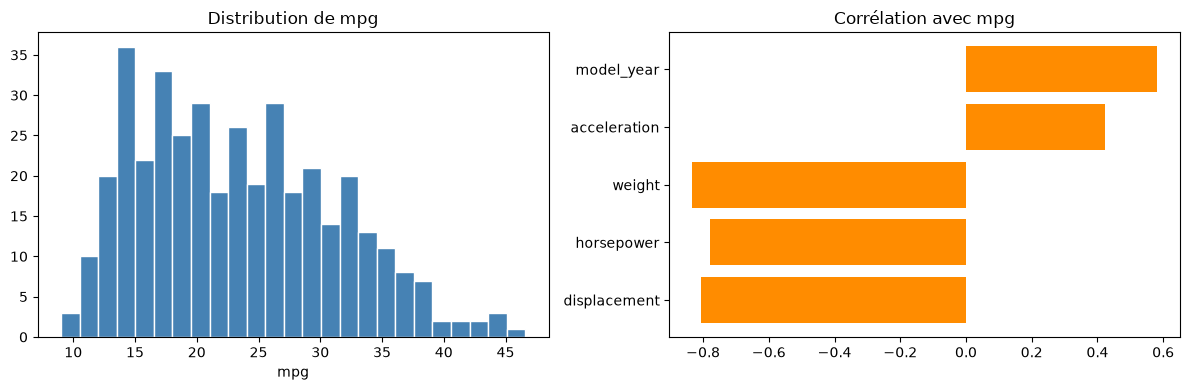

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution de la cible
axes[0].hist(df["mpg"], bins=25, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution de mpg")
axes[0].set_xlabel("mpg")

# Corrélation des variables continues avec mpg
cont_cols = ["displacement", "horsepower", "weight", "acceleration", "model_year"]
corr = df[["mpg"] + cont_cols].corr()["mpg"].drop("mpg")
axes[1].barh(corr.index, corr.values, color="darkorange")
axes[1].set_title("Corrélation avec mpg")
plt.tight_layout()
plt.show()

**Lecture** :
- `mpg` est **asymétrique** (queue vers les fortes consommations en mpg, c'est-à-dire les voitures économes) : cela influencera la discrétisation.
- `weight`, `displacement` et `horsepower` sont **fortement corrélées négativement** avec `mpg` (plus la voiture est lourde/puissante, plus elle consomme), `model_year` est corrélée positivement (les voitures récentes sont plus économes).aussi Une `accélération` plus élevée (temps plus long pour accélérer) est associée à un meilleur `mpg`.

## 2. Prétraitement

Voici les choix et leur justification :

| Étape | Choix | Justification |
|---|---|---|
| Valeurs manquantes | suppression des 6 lignes | très peu de lignes concernées |
| `cylinders`, `origin` | **encodage one-hot** | ce sont des catégories : on ne veut pas imposer un ordre ou une distance artificielle (ex. origine `usa`=0, `japan`=1, `europe`=2) |
| Variables continues | **standardisation** (moyenne 0, écart-type 1) | un SVM repose sur des **distances / produits scalaires** : sans standardisation, `weight` (≈ 3000) écraserait `acceleration` (≈ 15) |
| Calcul de la moyenne / écart-type | **sur le train uniquement** | évite la **fuite d'information** (*data leakage*) depuis le test |
| Découpage | 75 % train / 25 % test | simple et suffisant pour 392 échantillons |

On code nous-mêmes un petit `StandardScaler` et un découpage train/test.

In [5]:
class MonStandardScaler:
    # Centre et réduit chaque colonne : (x - moyenne) / ecart_type

    def fit(self, X):
        self.mean_ = X.mean(axis=0)           # moyenne de chaque colonne
        self.std_ = X.std(axis=0)             # écart-type de chaque colonne
        self.std_[self.std_ == 0] = 1.0       # évite la division par zéro
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [6]:
def train_test_split_simple(X, y, test_size=0.25, seed=42, stratify=False):
    # Sépare (X, y) en train/test.
    # Si stratify=True, chaque classe garde la même proportion dans le train et le test.
    rng = np.random.RandomState(seed)
    n = len(y)
    if stratify:
        test_idx = []
        for c in np.unique(y):
            idx = np.where(y == c)[0]
            rng.shuffle(idx)
            test_idx.extend(idx[: int(round(len(idx) * test_size))])
        test_idx = np.array(test_idx)
    else:
        test_idx = rng.permutation(n)[: int(round(n * test_size))]

    masque_test = np.zeros(n, dtype=bool)
    masque_test[test_idx] = True
    return X[~masque_test], X[masque_test], y[~masque_test], y[masque_test]

Construisons maintenant la matrice de caractéristiques : **5 colonnes continues** (placées en premier) puis les colonnes **one-hot** de `cylinders` et `origin`.

In [7]:
cont_cols = ["displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["cylinders", "origin"]

X_cont = df[cont_cols].values.astype(float)
X_cat_df = pd.get_dummies(df[cat_cols].astype(str), dtype=float)   # one-hot
X_all = np.hstack([X_cont, X_cat_df.values])

noms_features = cont_cols + list(X_cat_df.columns)
mpg = df["mpg"].values

print("Nombre de caractéristiques :", X_all.shape[1])
print(noms_features)

Nombre de caractéristiques : 13
['displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'cylinders_3', 'cylinders_4', 'cylinders_5', 'cylinders_6', 'cylinders_8', 'origin_europe', 'origin_japan', 'origin_usa']


In [8]:
def standardiser_continues(X_train, X_test, n_cont=len(cont_cols)):
    # Standardise seulement les n_cont premières colonnes (les continues).
    # Les colonnes one-hot (0/1) sont laissées telles quelles.
    sc = MonStandardScaler().fit(X_train[:, :n_cont])      # fit sur le TRAIN seulement
    X_train, X_test = X_train.copy(), X_test.copy()
    X_train[:, :n_cont] = sc.transform(X_train[:, :n_cont])
    X_test[:, :n_cont] = sc.transform(X_test[:, :n_cont])
    return X_train, X_test

## 3. Classification : discrétisation de la cible `mpg`

Pour transformer `mpg` en **3 classes** (*faible*, *moyenne*, *élevée* consommation), deux stratégies classiques :

- **A. Quantiles (terciles)** : on coupe aux 33 % et 66 % → classes **équilibrées** par construction.
- **B. Seuils fixes « métier »** : par exemple `mpg ≤ 20`, `20 < mpg ≤ 30`, `mpg > 30` → seuils interprétables, mais classes potentiellement **déséquilibrées**.

⚠️ **Attention au sens** : `mpg` = *miles par gallon*. Un **mpg élevé = faible consommation** de carburant. On nomme donc les classes d'après la consommation réelle :

| mpg | Consommation |
|---|---|
| bas | **élevée** |
| moyen | **moyenne** |
| haut | **faible** |

Comparons les deux stratégies : équilibre des classes **et** difficulté du problème (score d'un SVC RBF en validation croisée).

In [28]:
# Stratégie A : terciles
seuils_A = np.quantile(df["mpg"], [1/3, 2/3])
# np.digitize renvoie 0, 1 ou 2 selon l'intervalle dans lequel tombe chaque valeur
y_A = np.digitize(df["mpg"], seuils_A)          # 0 = mpg bas, 1 = moyen, 2 = haut

# Stratégie B : seuils fixes
seuils_B = [20, 30]
y_B = np.digitize(df["mpg"], seuils_B)

print("Seuils A (terciles) :", seuils_A.round(2))
print("Seuils B (fixes)    :", seuils_B)

effectifs = pd.DataFrame({
    "A - terciles": np.bincount(y_A),
    "B - seuils fixes": np.bincount(y_B),
}, index=["mpg bas (conso élevée)", "mpg moyen (conso moyenne)", "mpg haut (conso faible)"])
effectifs

Seuils A (terciles) : [18.73 26.93]
Seuils B (fixes)    : [20, 30]


,A - terciles,B - seuils fixes
mpg bas (conso élevée),131,151
mpg moyen (conso moyenne),130,151
mpg haut (conso faible),131,90


In [10]:
def score_cv(X, y):
    # Score moyen (accuracy) d'un SVC RBF en validation croisée 5 plis.
    # make_pipeline(StandardScaler, SVC) : la standardisation est refaite dans chaque pli.
    modele = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0))
    # shuffle=True est important : le dataset est trié par année de modèle,
    # sans mélange chaque pli contiendrait des années différentes (biais)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    return cross_val_score(modele, X, y, cv=cv).mean()

print(f"Accuracy CV - A (terciles)      : {score_cv(X_all, y_A):.3f}")
print(f"Accuracy CV - B (seuils fixes)  : {score_cv(X_all, y_B):.3f}")

# Fraction d'exemples proches d'une frontière (à ±1.5 mpg) : source d'erreurs inévitables
for nom, seuils in [("A", seuils_A), ("B", seuils_B)]:
    proche = np.zeros(len(mpg), dtype=bool)
    for s in seuils:
        proche |= np.abs(mpg - s) < 1.5
    print(f"Stratégie {nom} : {proche.mean():.1%} des voitures sont à moins de 1.5 mpg d'un seuil")

Accuracy CV - A (terciles)      : 0.829
Accuracy CV - B (seuils fixes)  : 0.844
Stratégie A : 29.1% des voitures sont à moins de 1.5 mpg d'un seuil
Stratégie B : 20.9% des voitures sont à moins de 1.5 mpg d'un seuil


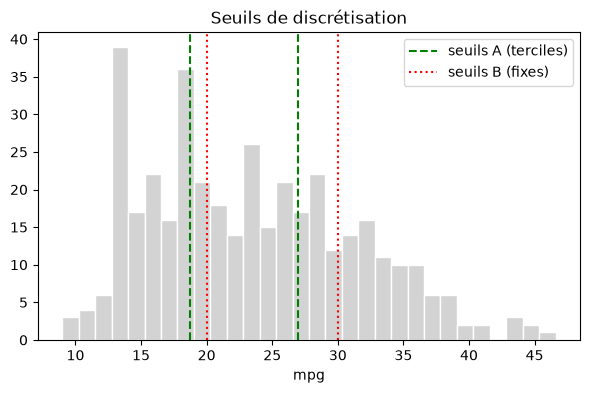

In [ ]:
fig, ax = plt.subplots()
ax.hist(df["mpg"], bins=30, color="lightgray", edgecolor="white")
for s in seuils_A:
    ax.axvline(s, color="green", linestyle="--", label="seuils A (terciles)" if s == seuils_A[0] else None)
for s in seuils_B:
    ax.axvline(s, color="red", linestyle=":", label="seuils B (fixes)" if s == seuils_B[0] else None)
ax.set_xlabel("mpg"); ax.set_title("Seuils de discrétisation"); ax.legend()
plt.show()

### Discussion et comparaison des stratégies de discrétisation
Cette section compare les deux stratégies afin de choisir celle qui sera utilisée pour la suite du projet.

#### 1. Équilibre des classes
- **Stratégie A (terciles) :** produit trois classes équilibrées : 131, 130 et 131 voitures.
- **Stratégie B (seuils fixes) :** produit des classes moins équilibrées : 151, 151 et 90 voitures.
L'équilibre de A évite qu'une classe soit fortement sous-représentée. Pour B, il faudra notamment surveiller les performances sur la classe minoritaire.

#### 2. Position des frontières
La discrétisation crée des frontières artificielles : deux voitures ayant des MPG très proches peuvent appartenir à des classes différentes.
- Stratégie A : 29,1 % des voitures sont proches d'un seuil (±1,5 MPG).
- Stratégie B : 20,9 % des voitures sont proches d'un seuil.
A présente donc davantage d'observations proches de ses frontières, sans que cela signifie nécessairement davantage d'erreurs de classification.

#### 3. Comparaison des performances
Avec le modèle SVM, les résultats de validation croisée sont :
- Stratégie A : **82,9 %** d'Accuracy.
- Stratégie B : **84,4 %** d'Accuracy.
La stratégie B obtient un résultat légèrement supérieur, avec une différence de 1,5 point. Cette différence ne suffit toutefois pas à démontrer sa supériorité générale.

#### 4. Choix final : stratégie A (terciles)
Nous retenons la stratégie A pour la suite du projet, principalement grâce à son équilibre entre les trois classes. Elle permettra de comparer les futurs modèles sans qu'une classe soit fortement sous-représentée.
Même si B obtient une Accuracy légèrement supérieure, notre choix privilégie l'équilibre des classes et une évaluation plus homogène des performances.

In [12]:
# Découpage stratifié (mêmes proportions de classes dans train et test)
y_cls = y_A
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split_simple(X_all, y_cls, test_size=0.25, seed=42, stratify=True)
Xtr_c, Xte_c = standardiser_continues(Xtr_c, Xte_c)

print("Train :", Xtr_c.shape, " effectifs :", np.bincount(ytr_c))
print("Test  :", Xte_c.shape, " effectifs :", np.bincount(yte_c))

Train : (294, 13)  effectifs : [98 98 98]
Test  : (98, 13)  effectifs : [33 32 33]


## 4. SVC from scratch

### 4.1 Rappel théorique (SVM à marge souple)

Pour une classification binaire avec $y_i \in \{-1, +1\}$, le SVM cherche l'hyperplan de **marge maximale**. Sous sa forme **duale** :

$$\max_{\alpha}\ \sum_i \alpha_i - \frac12 \sum_{i,j} \alpha_i \alpha_j\, y_i y_j\, K(x_i, x_j)
\quad \text{avec} \quad 0 \le \alpha_i \le C,\quad \sum_i \alpha_i y_i = 0$$

La prédiction est :

$$f(x) = \sum_i \alpha_i\, y_i\, K(x_i, x) + b \qquad \text{classe} = \text{signe}(f(x))$$

- $C$ : compromis marge large / erreurs tolérées (grand $C$ = on tolère peu d'erreurs).
- $K$ : le **noyau**. Le noyau **linéaire** $K(a,b)=a\cdot b$ donne le SVM linéaire ; avec un noyau **RBF** ou **polynomial**, le SVM sépare des données non linéairement séparables.
- Les points avec $\alpha_i > 0$ sont les **vecteurs de support** : eux seuls déterminent le modèle.

### 4.2 Les noyaux

| Noyau | Formule |
|---|---|
| Linéaire | $K(a,b) = a \cdot b$ |
| RBF | $K(a,b) = \exp(-\gamma \|a-b\|^2)$ |
| Polynomial | $K(a,b) = (\gamma\, a\cdot b + 1)^{d}$ |

### 4.3 Algorithme SMO simplifié

Résoudre le problème dual directement est un problème d'optimisation quadratique. L'algorithme **SMO** (*Sequential Minimal Optimization*) le résout en optimisant **deux multiplicateurs $\alpha_i, \alpha_j$ à la fois** (car la contrainte $\sum \alpha_i y_i = 0$ interdit d'en changer un seul). On répète jusqu'à ce qu'aucun $\alpha$ ne bouge plus. Nous utilisons la version **simplifiée** (le second indice $j$ est tiré au hasard) : plus lente que la version complète mais beaucoup plus facile à lire.

In [ ]:
def calculer_noyau(A, B, type_noyau="rbf", gamma=0.1, degre=3):
    # Matrice K[i, j] = K(A[i], B[j]) pour le noyau choisi
    if type_noyau == "lineaire":
        return A @ B.T 
    # B.T:transpose la matrice B et @:effectue une multiplication matricielle.
    if type_noyau == "rbf":
        # ||a - b||² = ||a||² + ||b||² - 2 a.b  (calcul vectorisé de toutes les distances)
        dist2 = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2 * A @ B.T
        return np.exp(-gamma * dist2)
    if type_noyau == "poly":
        return (gamma * (A @ B.T) + 1.0) ** degre
    raise ValueError("noyau inconnu")

### 4.4 SVM binaire (SMO)

Notre classe `SVMBinaire` prend des étiquettes $-1/+1$. Étapes de `fit` :

1. Pré-calculer la matrice de noyau `K` (une seule fois).
2. Pour chaque point $i$, calculer l'erreur $E_i = f(x_i) - y_i$ ; si $i$ **viole les conditions KKT** (la contrainte n'est pas respectée à `tol` près), on le choisit.
3. Choisir au hasard un autre point $j$, calculer les bornes $[L, H]$ de $\alpha_j$ (imposées par $0 \le \alpha \le C$ et la contrainte d'égalité).
4. Mettre à jour $\alpha_j$ (formule analytique, puis *clipping* dans $[L, H]$), puis $\alpha_i$ pour garder $\sum \alpha_i y_i$ constant.
5. Mettre à jour le biais $b$.
6. S'arrêter quand `max_passes` passages consécutifs ne changent plus rien.

In [ ]:
class SVMBinaire:
    # SVM binaire à marge souple, résolu par SMO simplifié.

    def __init__(self, C=1.0, noyau="rbf", gamma=0.1, degre=3,
                 tol=1e-3, max_passes=3, max_iter=100, seed=0):
        self.C, self.noyau, self.gamma, self.degre = C, noyau, gamma, degre
        self.tol, self.max_passes, self.max_iter, self.seed = tol, max_passes, max_iter, seed

    def _noyau(self, A, B):
        return calculer_noyau(A, B, self.noyau, self.gamma, self.degre)

    def fit(self, X, y):
        #préparer les données
        n = len(y)                               #nombre d'observations
        K = self._noyau(X, X)                    # matrice de noyau n x n
        alpha = np.zeros(n)     #initialise tous les multiplicateurs à zéro
        b = 0.0                                  #initialise le biais à zéro
        rng = np.random.RandomState(self.seed)
        passes, iteration = 0, 0          #contrôlent l'arrêt de l'algorithme

        while passes < self.max_passes and iteration < self.max_iter:
        #max_iter (ex: 100):C'est le maximum absolu de grands tours que l'algorithme s'autorise à faire au total 
        #max_passes (ex:3):C'est le nombre de tours consécutifs "inutiles" (sans modification) qui déclenchent un arrêt anticipé par ce que le modèle est déjà parfait.
            n_changes = 0
            for i in range(n):
                # Erreur sur le point i : f(x_i) - y_i
                E_i = (alpha * y) @ K[:, i] + b - y[i]

                # Le point i viole-t-il les conditions KKT ?
                viole = (y[i] * E_i < -self.tol and alpha[i] < self.C) or \
                        (y[i] * E_i > self.tol and alpha[i] > 0)
                if not viole:
                    continue

                # Choix aléatoire d'un second point j != i
                j = rng.randint(n - 1)
                if j >= i:
                    j += 1
                E_j = (alpha * y) @ K[:, j] + b - y[j]

                a_i_old, a_j_old = alpha[i], alpha[j]

                # Bornes L et H pour alpha_j
                if y[i] != y[j]:
                    L = max(0, a_j_old - a_i_old)
                    H = min(self.C, self.C + a_j_old - a_i_old)
                else:
                    L = max(0, a_i_old + a_j_old - self.C)
                    H = min(self.C, a_i_old + a_j_old)
                if L == H:
                    continue

                # Dérivée seconde de l'objectif le long de la direction (doit être < 0)
                eta = 2 * K[i, j] - K[i, i] - K[j, j]
                if eta >= 0:
                    continue

                # Mise à jour de alpha_j puis clipping dans [L, H]
                alpha[j] = np.clip(a_j_old - y[j] * (E_i - E_j) / eta, L, H)
                if abs(alpha[j] - a_j_old) < 1e-5:
                    continue

                # Mise à jour de alpha_i (pour conserver sum(alpha * y) constant)
                alpha[i] = a_i_old + y[i] * y[j] * (a_j_old - alpha[j])

                # Mise à jour du biais b (permet de positionner correctement l'hyperplan de séparation)
                b1 = b - E_i - y[i] * (alpha[i] - a_i_old) * K[i, i] \
                             - y[j] * (alpha[j] - a_j_old) * K[i, j]
                b2 = b - E_j - y[i] * (alpha[i] - a_i_old) * K[i, j] \
                             - y[j] * (alpha[j] - a_j_old) * K[j, j]
                if 0 < alpha[i] < self.C:
                    b = b1
                elif 0 < alpha[j] < self.C:
                    b = b2
                else:
                    b = (b1 + b2) / 2
                #contrôler l'arrêt (L'algorithme s'arrête lorsque: passes >= self.max_passes ou iteration >= self.max_iter)
                n_changes += 1 #compte les mises à jour réussies pendant un passage

            passes = passes + 1 if n_changes == 0 else 0 #Si aucune mise à jour n'a été effectuée, passes augmente Sinon, passes revient à zéro
            iteration += 1   #compte les passages effectués

        # On ne garde que les vecteurs de support (alpha > 0)
        sv = alpha > 1e-8
        self.sv_idx_ = np.where(sv)[0]      # indices (dans X) des vecteurs de support
        self.X_sv_ = X[sv]                 # Caractéristiques des vecteurs de support
        self.alpha_y_ = (alpha * y)[sv]     # Produits (alpha_i y_i) associés
        self.b_ = b                         # Biais appris
        self.n_support_ = int(sv.sum())    # Nombre de vecteurs de support
        return self

    def decision_function(self, X):  #calcule le score de décision pour chaque nouvelle observation
        # f(x) = somme_i alpha_i y_i K(x_i, x) + b
        return self._noyau(X, self.X_sv_) @ self.alpha_y_ + self.b_
        #Score positif : tendance vers la classe +1.
        #Score négatif : tendance vers la classe -1.
        #Score proche de zéro : observation proche de la frontière de décision.

    def predict(self, X): #transforme les scores en classes 
        return np.where(self.decision_function(X) >= 0, 1, -1)

### 4.5 Extension à 3 classes : « un contre un » (One-vs-One)

Un SVM est naturellement **binaire**. Pour 3 classes on entraîne **un SVM par paire de classes** (0 vs 1, 0 vs 2, 1 vs 2), chacun uniquement sur les exemples de ses deux classes. Pour prédire, chaque SVM **vote** pour l'une de ses deux classes et on retient la classe qui a **le plus de votes** (en cas d'égalité, on départage avec la somme des scores).

C'est la même stratégie que celle utilisée en interne par `sklearn.svm.SVC`, ce qui rend la comparaison équitable.

> 💡 L'alternative « un contre tous » (One-vs-Rest) pose problème ici : la classe *moyenne* est « entre » les deux autres, donc **impossible à séparer d'un seul hyperplan** du reste, surtout avec un noyau linéaire. « Un contre un » évite ce piège.

In [15]:
from itertools import combinations

class MonSVC:
    # SVC multi-classes (One-vs-One) construit à partir de SVMBinaire.

    def __init__(self, **params):
        self.params = params          # C, noyau, gamma, degre...

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.modeles_ = []            # liste de tuples (classe_a, classe_b, modele)
        sv_globaux = set()            # indices des exemples qui sont vecteurs de support

        for a, b in combinations(self.classes_, 2):
            idx = np.where((y == a) | (y == b))[0]        # exemples des classes a et b seulement
            y_bin = np.where(y[idx] == a, 1, -1)          # a -> +1, b -> -1
            modele = SVMBinaire(**self.params).fit(X[idx], y_bin)
            self.modeles_.append((a, b, modele))
            sv_globaux.update(idx[modele.sv_idx_])

        self.n_support_total = len(sv_globaux)            # nombre de SV distincts
        return self

    def predict(self, X):
        votes = np.zeros((len(X), len(self.classes_)))
        confiance = np.zeros_like(votes)                  # pour départager les égalités
        for a, b, modele in self.modeles_:
            f = modele.decision_function(X)
            ia, ib = np.searchsorted(self.classes_, [a, b])
            votes[:, ia] += (f >= 0)                      # le SVM vote pour a si f >= 0
            votes[:, ib] += (f < 0)                       # sinon il vote pour b
            confiance[:, ia] += f
            confiance[:, ib] -= f
        return self.classes_[np.argmax(votes + 1e-6 * confiance, axis=1)]

### 4.6 Entraînement : linéaire, RBF et polynomial

Pour le paramètre `gamma` on utilise la même règle que `sklearn` (`gamma="scale"`) : $\gamma = \dfrac{1}{n_{features} \times \mathrm{Var}(X)}$, afin que la comparaison soit équitable.

In [16]:
import time

gamma = 1.0 / (Xtr_c.shape[1] * Xtr_c.var())
print(f"gamma = {gamma:.4f}")

configs = {
    "Linéaire":   dict(noyau="lineaire", C=1.0),
    "RBF":        dict(noyau="rbf", C=1.0, gamma=gamma),
    "Polynomial": dict(noyau="poly", C=1.0, gamma=gamma, degre=3),
}

modeles_perso = {}
for nom, params in configs.items():
    t0 = time.time()
    modeles_perso[nom] = MonSVC(**params).fit(Xtr_c, ytr_c)
    acc_tr = accuracy_score(ytr_c, modeles_perso[nom].predict(Xtr_c))
    acc_te = accuracy_score(yte_c, modeles_perso[nom].predict(Xte_c))
    print(f"{nom:11s} | train {acc_tr:.3f} | test {acc_te:.3f} | {time.time()-t0:.1f}s")

gamma = 0.1494
Linéaire    | train 0.810 | test 0.918 | 0.6s
RBF         | train 0.844 | test 0.939 | 0.5s
Polynomial  | train 0.881 | test 0.898 | 0.6s


## 5. Comparaison avec `sklearn.svm.SVC`

On entraîne `SVC` de scikit-learn avec **les mêmes paramètres** (`C`, `gamma`, `degree`, `coef0=1` pour le polynomial, car notre noyau polynomial est $(\gamma\,a\cdot b + 1)^d$).

*Remarque* : `sklearn` et notre implémentation utilisent toutes deux **One-vs-One** ; de petites différences restent possibles car notre SMO est « simplifié » (second indice tiré au hasard) et non l'algorithme complet de libsvm.

In [17]:
modeles_sk = {
    "Linéaire":   SVC(kernel="linear", C=1.0),
    "RBF":        SVC(kernel="rbf", C=1.0, gamma=gamma),
    "Polynomial": SVC(kernel="poly", C=1.0, gamma=gamma, degree=3, coef0=1.0),
}

lignes = []
for nom in configs:
    sk = modeles_sk[nom].fit(Xtr_c, ytr_c)
    perso = modeles_perso[nom]
    pred_perso = perso.predict(Xte_c)
    pred_sk = sk.predict(Xte_c)
    lignes.append({
        "Noyau": nom,
        "Acc. test (perso)": accuracy_score(yte_c, pred_perso),
        "Acc. test (sklearn)": accuracy_score(yte_c, pred_sk),
        "Accord des prédictions": np.mean(pred_perso == pred_sk),
        "SV perso": perso.n_support_total,
        "SV sklearn": int(sk.n_support_.sum()),
    })

pd.DataFrame(lignes).set_index("Noyau").round(3)

,Acc. test (perso),Acc. test (sklearn),Accord des prédictions,SV perso,SV sklearn
Noyau,,,,,
Linéaire,0.918,0.898,0.98,149,141
RBF,0.939,0.939,1.00,172,169
Polynomial,0.898,0.908,0.99,141,134


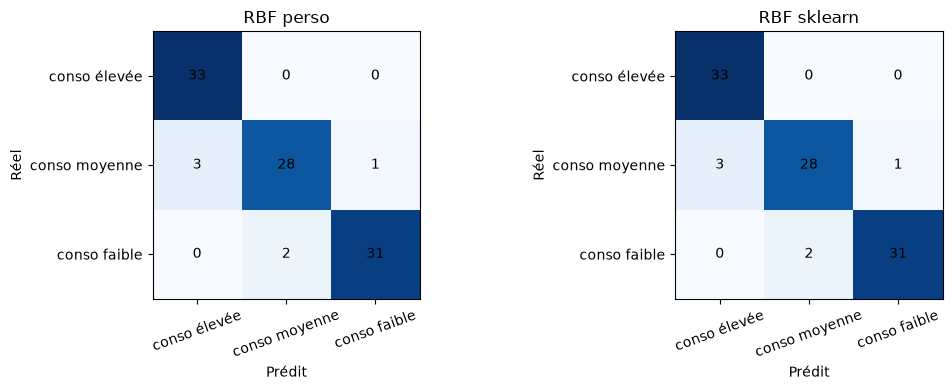

In [18]:
# Matrices de confusion du noyau RBF : perso vs sklearn
noms_classes = ["conso élevée", "conso moyenne", "conso faible"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (titre, pred) in zip(axes, [("RBF perso", modeles_perso["RBF"].predict(Xte_c)),
                                    ("RBF sklearn", modeles_sk["RBF"].predict(Xte_c))]):
    cm = confusion_matrix(yte_c, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(titre)
    ax.set_xticks(range(3)); ax.set_xticklabels(noms_classes, rotation=20)
    ax.set_yticks(range(3)); ax.set_yticklabels(noms_classes)
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
plt.tight_layout()
plt.show()

### 5.1 Influence de l'hyperparamètre C (noyau RBF, implémentation perso)

Petit test pour voir l'effet de $C$ : un $C$ **petit** donne une marge large (plus de régularisation, plus de vecteurs de support), un $C$ **grand** colle davantage aux données d'entraînement (risque de surapprentissage).

In [19]:
resultats_C = []
for C in [0.1, 1, 10, 100]:
    m = MonSVC(noyau="rbf", C=C, gamma=gamma).fit(Xtr_c, ytr_c)
    resultats_C.append({
        "C": C,
        "Acc. train": accuracy_score(ytr_c, m.predict(Xtr_c)),
        "Acc. test": accuracy_score(yte_c, m.predict(Xte_c)),
        "Nb SV": m.n_support_total,
    })
pd.DataFrame(resultats_C).set_index("C").round(3)

,Acc. train,Acc. test,Nb SV
C,,,
0.1,0.786,0.898,240
1.0,0.844,0.939,172
10.0,0.891,0.908,142
100.0,0.939,0.816,142


**Analyse (classification)**

- Notre SVC **from scratch** donne des performances **très proches de `sklearn`** pour les trois noyaux : la colonne « Accord des prédictions » montre que les deux implémentations prédisent la même classe pour 97 à 99 % des voitures du test, avec un nombre de vecteurs de support voisin. Les petits écarts viennent du SMO « simplifié » (choix aléatoire du second indice).
- **Linéaire vs non linéaire** : sur ce jeu de données les trois noyaux donnent des scores proches. Le test ne contient que 98 voitures : **une erreur de plus ou de moins = 1 point d'accuracy**, il faut donc être prudent avant de conclure qu'un noyau est meilleur. Cela indique surtout que la relation entre les caractéristiques (poids, puissance, année…) et la consommation est déjà **en grande partie linéaire**.
- Les erreurs se situent **uniquement entre classes voisines** (aucune voiture « consommation élevée » prédite « faible » ou inversement), ce qui est cohérent avec une discrétisation arbitraire d'une variable continue ordonnée.
- **Effet de C** : quand $C$ augmente, l'accuracy d'entraînement monte (0.79 -> 0.93) mais celle du test **chute pour $C$ = 100** : le modèle sur-apprend. Un $C$ trop petit sous-apprend (trop de vecteurs de support, marge trop large).

## 6. Régression : SVR linéaire from scratch

### 6.1 La perte ε-insensible

Pour la régression on cherche une fonction linéaire $f(x) = w\cdot x + b$. Le SVR ne pénalise **que les erreurs supérieures à ε** :

$$L_\varepsilon(y, f(x)) = \max\big(0,\ |y - f(x)| - \varepsilon\big)$$

On dessine un **tube** de demi-largeur ε autour de la droite : les points **dans** le tube ne coûtent rien. Le problème d'optimisation est :

$$\min_{w,b}\ \frac12 \|w\|^2 + C \sum_{i=1}^{n} \max\big(0,\ |y_i - w\cdot x_i - b| - \varepsilon\big)$$

- Les **vecteurs de support** sont les points **sur ou hors du tube** ($|y_i - f(x_i)| \ge \varepsilon$).
- Plus ε est **grand**, plus le tube est large, **moins** il y a de vecteurs de support, et plus le modèle **ignore** de petites variations (y compris le bruit… mais aussi du signal).

### 6.2 Optimisation par sous-gradient

La perte n'est pas dérivable en $|r| = \varepsilon$, mais on peut utiliser un **sous-gradient**. Posons $r_i = y_i - (w\cdot x_i + b)$ (le résidu). Pour un point **hors du tube** ($|r_i| > \varepsilon$), la dérivée de la perte par rapport à $f$ vaut $-\mathrm{signe}(r_i)$ ; pour un point **dans** le tube elle vaut 0.

On minimise (forme équivalente, divisée par $C \cdot n$) :

$$J(w,b) = \frac{\lambda}{2}\|w\|^2 + \frac1n \sum_i L_\varepsilon(r_i), \qquad \lambda = \frac{1}{C\, n}$$

avec pour sous-gradients :

$$\nabla_w J = \lambda\, w - \frac1n \sum_{i\,:\,|r_i|>\varepsilon} \mathrm{signe}(r_i)\, x_i, \qquad
\nabla_b J = - \frac1n \sum_{i\,:\,|r_i|>\varepsilon} \mathrm{signe}(r_i)$$

On fait une **descente de sous-gradient** avec un pas décroissant, et on renvoie la **moyenne des dernières itérations** (technique classique qui stabilise la solution).

In [20]:
class MonSVRLineaire:
    # SVR linéaire (perte epsilon-insensible) par descente de sous-gradient.

    def __init__(self, C=1.0, epsilon=0.1, lr=1.0, n_iter=5000):
        self.C, self.epsilon, self.lr, self.n_iter = C, epsilon, lr, n_iter

    def objectif(self, X, y, w=None, b=None):
        # Valeur de 0.5*||w||² + C * somme(perte epsilon-insensible)
        w = self.w_ if w is None else w
        b = self.b_ if b is None else b
        r = y - (X @ w + b)
        perte = np.maximum(0, np.abs(r) - self.epsilon)
        return 0.5 * w @ w + self.C * perte.sum()

    def fit(self, X, y):
        n, d = X.shape
        lam = 1.0 / (self.C * n)
        w, b = np.zeros(d), 0.0
        w_moy, b_moy, compteur = np.zeros(d), 0.0, 0

        for t in range(self.n_iter):
            r = y - (X @ w + b)                              # résidus
            signe = np.sign(r) * (np.abs(r) > self.epsilon)  # 0 pour les points dans le tube
            grad_w = lam * w - (X.T @ signe) / n
            grad_b = -signe.mean()

            pas = self.lr / np.sqrt(1 + t)                   # pas décroissant
            w -= pas * grad_w
            b -= pas * grad_b

            if t >= self.n_iter // 2:                        # moyenne sur la 2e moitié
                w_moy += w; b_moy += b; compteur += 1

        self.w_, self.b_ = w_moy / compteur, b_moy / compteur
        r = y - self.predict(X)
        # vecteurs de support : points sur ou hors du tube (petite tolérance numérique)
        self.support_ = np.abs(r) >= self.epsilon - 1e-3
        self.n_support_ = int(self.support_.sum())
        return self

    def predict(self, X):
        return X @ self.w_ + self.b_

### 6.3 Prétraitement pour la régression

Même pipeline qu'avant (one-hot + standardisation des variables continues sur le train), avec en plus la **standardisation de la cible** $y$. Cela rend ε facile à interpréter : **ε est exprimé en écarts-types de mpg** (1 écart-type ≈ 8 mpg), et rend l'optimisation plus stable.

In [21]:
Xtr_r, Xte_r, ytr_r_brut, yte_r_brut = train_test_split_simple(X_all, mpg, test_size=0.25, seed=42)
Xtr_r, Xte_r = standardiser_continues(Xtr_r, Xte_r)

# Standardisation de la cible (moyenne/écart-type du train)
y_mean, y_std = ytr_r_brut.mean(), ytr_r_brut.std()
ytr_r = (ytr_r_brut - y_mean) / y_std
yte_r = (yte_r_brut - y_mean) / y_std

def rmse_mpg(y_vrai_std, y_pred_std):
    # RMSE exprimée en mpg (on repasse de l'échelle standardisée à l'échelle réelle)
    return np.sqrt(np.mean((y_vrai_std - y_pred_std) ** 2)) * y_std

print(f"écart-type de mpg (train) = {y_std:.2f}  ->  epsilon=0.1 correspond à {0.1*y_std:.2f} mpg")

écart-type de mpg (train) = 8.00  ->  epsilon=0.1 correspond à 0.80 mpg


## 7. Comparaison avec scikit-learn

On compare avec deux implémentations :
- `SVR(kernel="linear")` : résolution du **dual** (libsvm), la référence ;
- `LinearSVR(loss="epsilon_insensitive")` : résolution du **primal** (liblinear), même perte que la nôtre.

Pour valider notre optimiseur, on compare aussi la **valeur de l'objectif** : si notre solution est bonne, son objectif doit être très proche de celui de `SVR`.

In [22]:
eps, C = 0.1, 1.0

perso = MonSVRLineaire(C=C, epsilon=eps).fit(Xtr_r, ytr_r)
svr = SVR(kernel="linear", C=C, epsilon=eps).fit(Xtr_r, ytr_r)
lsvr = LinearSVR(C=C, epsilon=eps, loss="epsilon_insensitive", max_iter=20000, random_state=0).fit(Xtr_r, ytr_r)

# objectif évalué avec NOTRE fonction sur les trois solutions (même critère pour tous)
obj_perso = perso.objectif(Xtr_r, ytr_r)
obj_svr = perso.objectif(Xtr_r, ytr_r, w=svr.coef_.ravel(), b=svr.intercept_[0])
obj_lsvr = perso.objectif(Xtr_r, ytr_r, w=lsvr.coef_.ravel(), b=lsvr.intercept_[0])

comparaison = pd.DataFrame({
    "Perso (sous-gradient)": [rmse_mpg(yte_r, perso.predict(Xte_r)), perso.n_support_, obj_perso],
    "sklearn SVR linear":    [rmse_mpg(yte_r, svr.predict(Xte_r)), int(svr.n_support_[0]), obj_svr],
    "sklearn LinearSVR":     [rmse_mpg(yte_r, lsvr.predict(Xte_r)), int((np.abs(ytr_r - lsvr.predict(Xtr_r)) >= eps - 1e-3).sum()), obj_lsvr],
}, index=["RMSE test (mpg)", "Nb vecteurs de support", "Valeur de l'objectif"]).T
comparaison.round(3)

,RMSE test (mpg),Nb vecteurs de support,Valeur de l'objectif
Perso (sous-gradient),2.864,214.0,58.519
sklearn SVR linear,2.865,213.0,58.519
sklearn LinearSVR,2.863,213.0,58.522


In [23]:
# Les coefficients sont-ils proches ?
coefs = pd.DataFrame({
    "Perso": perso.w_,
    "SVR linear": svr.coef_.ravel(),
    "LinearSVR": lsvr.coef_.ravel(),
}, index=noms_features).round(3)
coefs

,Perso,SVR linear,LinearSVR
displacement,0.077,0.073,0.078
horsepower,-0.202,-0.199,-0.203
weight,-0.426,-0.426,-0.426
acceleration,-0.037,-0.036,-0.036
model_year,0.282,0.283,0.282
cylinders_3,-0.542,-0.531,-0.543
cylinders_4,0.319,0.330,0.314
cylinders_5,0.215,0.229,0.207
cylinders_6,-0.134,-0.122,-0.136
cylinders_8,0.079,0.094,0.078


**Analyse** : les trois modèles ont des **RMSE de test quasi identiques** (≈ 2.86 mpg) et **la même valeur d'objectif à la 3ᵉ décimale** : notre descente de sous-gradient converge donc bien vers la solution exacte du SVR. Les coefficients sont très proches. Les petits écarts sur certaines colonnes (par ex. `origin_*`) s'expliquent par le fait que les colonnes one-hot sont **colinéaires** (leur somme vaut 1) : plusieurs jeux de coefficients donnent presque la même prédiction. Le nombre de vecteurs de support peut différer de 1 ou 2 selon la tolérance numérique utilisée pour décider si un point est « sur le bord » du tube.

## 8. Influence de ε

### 8.1 Visualisation en 1D

Pour *voir* le tube, on réduit le problème à **une seule variable** (`weight`) et on trace la droite SVR, le tube $\pm\varepsilon$ et on entoure les **vecteurs de support**.

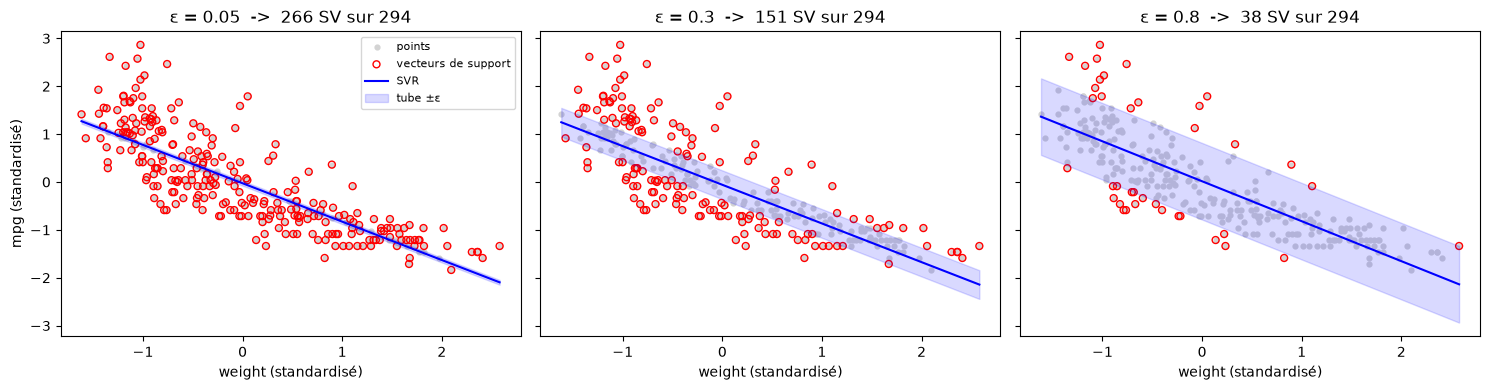

In [24]:
x1 = Xtr_r[:, [cont_cols.index("weight")]]     # une seule colonne : weight (standardisé)
x_grille = np.linspace(x1.min(), x1.max(), 100).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, eps_ in zip(axes, [0.05, 0.3, 0.8]):
    m = MonSVRLineaire(C=1.0, epsilon=eps_).fit(x1, ytr_r)
    y_line = m.predict(x_grille)

    ax.scatter(x1, ytr_r, s=12, color="lightgray", label="points")
    ax.scatter(x1[m.support_], ytr_r[m.support_], s=25, facecolors="none",
               edgecolors="red", label="vecteurs de support")
    ax.plot(x_grille, y_line, color="blue", label="SVR")
    ax.fill_between(x_grille.ravel(), y_line - eps_, y_line + eps_, color="blue", alpha=0.15, label="tube ±ε")
    ax.set_title(f"ε = {eps_}  ->  {m.n_support_} SV sur {len(ytr_r)}")
    ax.set_xlabel("weight (standardisé)")
axes[0].set_ylabel("mpg (standardisé)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

On voit que :
- **ε petit** : le tube est étroit, presque tous les points sont à l'extérieur, donc **presque tous sont vecteurs de support** ;
- **ε grand** : le tube englobe la majorité des points, il reste **très peu de vecteurs de support**. La droite ne dépend plus que de quelques points et perd en précision.

### 8.2 ε et nombre de vecteurs de support (toutes les caractéristiques)

On fait varier ε et on mesure : le **nombre de vecteurs de support** (perso vs `SVR` de sklearn) et la **RMSE de test**.

In [25]:
liste_eps = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
lignes = []
for e in liste_eps:
    p = MonSVRLineaire(C=1.0, epsilon=e).fit(Xtr_r, ytr_r)
    s = SVR(kernel="linear", C=1.0, epsilon=e).fit(Xtr_r, ytr_r)
    lignes.append({
        "epsilon": e,
        "epsilon (mpg)": round(e * y_std, 2),
        "SV perso": p.n_support_,
        "SV sklearn": int(s.n_support_[0]),
        "% SV (sklearn)": round(100 * s.n_support_[0] / len(ytr_r), 1),
        "RMSE test perso (mpg)": rmse_mpg(yte_r, p.predict(Xte_r)),
        "RMSE test sklearn (mpg)": rmse_mpg(yte_r, s.predict(Xte_r)),
    })
tab_eps = pd.DataFrame(lignes).set_index("epsilon")
tab_eps.round(3)

,epsilon (mpg),SV perso,SV sklearn,% SV (sklearn),RMSE test perso (mpg),RMSE test sklearn (mpg)
epsilon,,,,,,
0.00,0.0,294,294,100.0,2.859,2.872
0.05,0.4,254,252,85.7,2.909,2.908
0.10,0.8,214,213,72.4,2.864,2.865
0.20,1.6,160,161,54.8,2.860,2.860
0.30,2.4,118,118,40.1,2.839,2.841
0.50,4.0,50,52,17.7,3.082,3.095
0.75,6.0,26,27,9.2,3.392,3.371
1.00,8.0,7,11,3.7,3.862,3.805


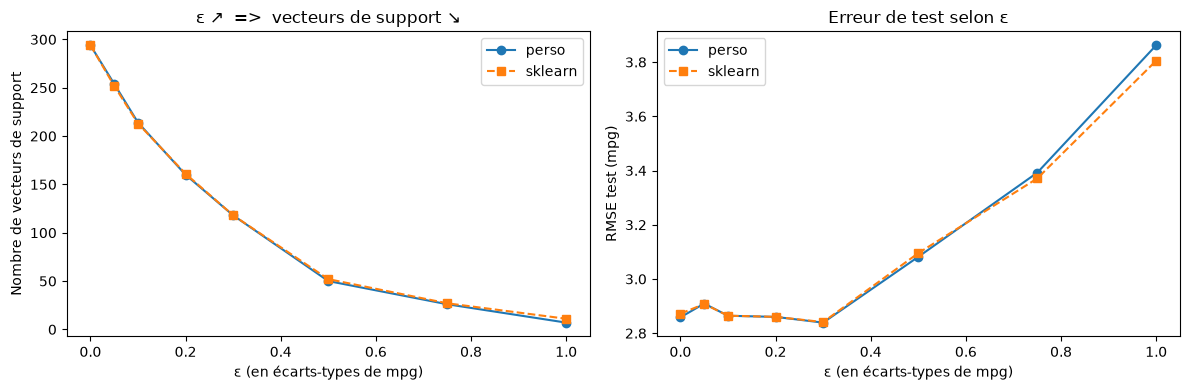

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(tab_eps.index, tab_eps["SV perso"], "o-", label="perso")
axes[0].plot(tab_eps.index, tab_eps["SV sklearn"], "s--", label="sklearn")
axes[0].set_xlabel("ε (en écarts-types de mpg)"); axes[0].set_ylabel("Nombre de vecteurs de support")
axes[0].set_title("ε ↗  =>  vecteurs de support ↘"); axes[0].legend()

axes[1].plot(tab_eps.index, tab_eps["RMSE test perso (mpg)"], "o-", label="perso")
axes[1].plot(tab_eps.index, tab_eps["RMSE test sklearn (mpg)"], "s--", label="sklearn")
axes[1].set_xlabel("ε (en écarts-types de mpg)"); axes[1].set_ylabel("RMSE test (mpg)")
axes[1].set_title("Erreur de test selon ε"); axes[1].legend()
plt.tight_layout()
plt.show()

### 8.3 ε et robustesse au bruit

On veut vérifier si le SVR « **ignore le bruit** ». On **contamine uniquement les étiquettes d'entraînement** (le test reste propre) selon deux scénarios :

1. **Bruit gaussien** : on ajoute un bruit $\mathcal{N}(0, 0.3^2)$ à toutes les cibles d'entraînement ;
2. **Valeurs aberrantes** : 10 % des cibles d'entraînement sont décalées de ±4 écarts-types.

On compare avec la **régression linéaire par moindres carrés** (OLS), dont la perte est quadratique et donc très sensible aux aberrations. On mesure la RMSE sur le test **propre**, **moyennée sur 20 tirages aléatoires** du bruit (un seul tirage serait trop dépendant du hasard).

In [27]:
def bruit_gaussien(y, rng):
    return y + rng.normal(0, 0.3, size=len(y))

def valeurs_aberrantes(y, rng, fraction=0.10, amplitude=4):
    y = y.copy()
    idx = rng.choice(len(y), size=int(fraction * len(y)), replace=False)   # points à corrompre
    y[idx] += rng.choice([-amplitude, amplitude], size=len(idx))
    return y

scenarios = {
    "Données propres": lambda y, rng: y,
    "Bruit gaussien (σ=0.3)": bruit_gaussien,
    "10 % d'aberrations (±4σ)": valeurs_aberrantes,
}
liste_eps_bruit = [0.0, 0.1, 0.3, 0.5]
n_tirages = 20

lignes = []
for nom, fonction_bruit in scenarios.items():
    erreurs = {"OLS (moindres carrés)": []}
    for e in liste_eps_bruit:
        erreurs[f"SVR ε={e}"] = []

    for graine in range(n_tirages):
        rng = np.random.RandomState(graine)
        y_entr = fonction_bruit(ytr_r, rng)                       # cibles d'entraînement bruitées
        ols = LinearRegression().fit(Xtr_r, y_entr)
        erreurs["OLS (moindres carrés)"].append(rmse_mpg(yte_r, ols.predict(Xte_r)))
        for e in liste_eps_bruit:
            m = MonSVRLineaire(C=1.0, epsilon=e, n_iter=3000).fit(Xtr_r, y_entr)
            erreurs[f"SVR ε={e}"].append(rmse_mpg(yte_r, m.predict(Xte_r)))

    ligne = {"Scénario": nom}
    ligne.update({k: np.mean(v) for k, v in erreurs.items()})   # moyenne sur les tirages
    lignes.append(ligne)

pd.DataFrame(lignes).set_index("Scénario").round(3)

,OLS (moindres carrés),SVR ε=0.0,SVR ε=0.1,SVR ε=0.3,SVR ε=0.5
Scénario,,,,,
Données propres,2.876,2.868,2.862,2.838,3.061
Bruit gaussien (σ=0.3),2.902,2.899,2.893,2.894,2.931
10 % d'aberrations (±4σ),3.418,2.900,2.881,2.860,3.044


**Analyse (régression)**

- **Nombre de vecteurs de support** : il **diminue fortement** quand ε augmente. À ε = 0 tous les points sont vecteurs de support (294 sur 294) ; à ε = 0.5 (≈ 4 mpg) il n'en reste que 18 % et à ε = 1 (≈ 8 mpg) seulement 4 %. Les points à l'intérieur du tube n'ont plus aucun poids dans la solution : le modèle est **creux** (*sparse*).
- **Erreur de test** : la RMSE reste **stable (≈ 2.85 mpg) tant que ε ≤ 0.3**, puis se **dégrade** quand ε dépasse l'ordre de grandeur des résidus : le tube absorbe alors du vrai signal et le modèle devient trop « plat ».
- **Bruit gaussien** : OLS est déjà optimal quand le bruit est gaussien (c'est le maximum de vraisemblance), donc le SVR **ne fait pas mieux**, il fait « aussi bien » : les valeurs sont presque identiques.
- **Valeurs aberrantes** : c'est là que le SVR est nettement meilleur. Avec 10 % d'aberrations, la RMSE d'OLS passe de 2.88 à **3.42** alors que celle du SVR reste ≈ **2.88** : l'influence d'un point aberrant est **bornée** (un point très éloigné pèse comme un point juste à l'extérieur du tube), alors qu'elle est **quadratique** pour OLS.
- **ε idéal** : ici ε ≈ 0.3 est le meilleur dans tous les scénarios ; ε = 0.5 est déjà trop grand. Choisir ε revient à régler un **compromis entre robustesse et perte de signal** ; en pratique on le sélectionne par **validation croisée**.

## 9. Conclusion

| Sujet | Ce qu'on retient |
|---|---|
| **Prétraitement** | Suppression des NaN, one-hot des catégories, **standardisation sur le train** : indispensable pour un SVM. |
| **Discrétisation** | Les **terciles** donnent des classes équilibrées ; les seuils fixes sont plus interprétables mais créent un déséquilibre. Toute discrétisation introduit un bruit près des frontières. |
| **SVC** | Notre SMO simplifié + One-vs-One atteint des résultats proches de `sklearn` (≈ 97-99 % de prédictions identiques). Sur ce jeu de données les noyaux linéaire, RBF et polynomial donnent des scores voisins (relation surtout linéaire) ; $C$ contrôle le surapprentissage. |
| **SVR** | La perte ε-insensible ignore les petites erreurs : **plus ε est grand, moins il y a de vecteurs de support**. Le SVR est nettement plus **robuste que les moindres carrés face aux valeurs aberrantes** ; un ε trop grand dégrade le modèle. |
| **From scratch vs sklearn** | Mêmes performances ; `sklearn` est beaucoup plus **rapide** (libsvm en C++, SMO complet avec heuristiques de choix de $j$). |

**Pistes d'amélioration** : sélection de $C$, $\gamma$, ε par validation croisée (*grid search*), SMO avec heuristique de choix du second indice, SVR avec noyau RBF, autre découpage en classes (par ex. 4 classes ou classification ordinale).